# Знаковая карта Шухарта (Shewhart Sign Chart)

**Непараметрическая (distribution-free) контрольная карта Шухарта для контроля
положения процесса по знакам отклонений наблюдений от целевого значения $\mu_0$.**

Источник: Chakraborti, S. & Graham, M. A. (2019). *Nonparametric Statistical
Process Control*, Wiley.

- § 4.2.1.1.1 «A Shewhart Sign Chart» — стр. 189–196;
- определение distribution-free — стр. 188.

> **Численные примеры книги (4.1–4.3) здесь не воспроизводятся** — они вынесены в
> автотесты `tests/sign/` (один файл — один пример). Этот ноутбук показывает теорию
> и возможности библиотеки `nonparametric-charts`.

## 1. Импорты и настройка

Запуск из каталога `notebooks/`; каталог `src` добавляется в `sys.path` (пакет `nonparametric_charts`).
Графики — в едином минималистичном LaTeX-стиле проекта
(`nonparametric_charts.utils.plot_style.apply_minimal_latex_style`).

In [1]:
import sys
from pathlib import Path

sys.path.append('../src')      # пакет nonparametric_charts (запуск из notebooks/)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import comb
from scipy import stats

from nonparametric_charts.utils.plot_style import apply_minimal_latex_style
from nonparametric_charts.utils import DataLoader, DataPreprocessor
from nonparametric_charts.charts.sign_chart import SignChart

apply_minimal_latex_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.precision', 6)

ROOT = Path('..').resolve()
print('Корень проекта:', ROOT)

Корень проекта: /home/nebolsinvasili/repo/nonparametric-charts


## 2. Теория

### 2.1. Постановка задачи *(§ 4.2.1.1.1, стр. 189)*

Через равные промежутки времени берутся независимые подгруппы размера $n$:

$$X_{i1},\ X_{i2},\ \ldots,\ X_{in},\qquad i = 1, 2, 3, \ldots$$

**Предположения (Case K — целевое значение известно):**

1. Наблюдения независимы внутри подгруппы и между подгруппами.
2. Распределение $F$ непрерывно, конкретный вид не известен.
3. Целевое значение $\mu_0$ (IC-медиана) известно.

Контролируется **сдвиг медианы** от $\mu_0$ вверх или вниз.

### 2.2. Знаки отклонений *(стр. 189–190, ур. 4.2)*

$$\phi(t) = \begin{cases} 1, & t > 0 \\ 0, & t = 0 \\ -1, & t < 0 \end{cases}$$

Так как $\mu_0$ — медиана непрерывного распределения,
$P(X_{ij} > \mu_0) = P(X_{ij} < \mu_0) = \tfrac12$ и $P(X_{ij} = \mu_0) = 0$.
Значит, индикатор $Y_{ij} = \mathbb{1}(X_{ij} > \mu_0) \sim \mathrm{Bernoulli}(1/2)$
**при любом непрерывном $F$** — в этом источник distribution-free свойства.

### 2.3. Знаковая статистика *(стр. 190, ур. 4.1)*

$$SN_i = \sum_{j=1}^{n} \phi(X_{ij} - \mu_0) = n_i^+ - n_i^- = 2T_i - n,
\qquad T_i = n_i^+ = \sum_{j=1}^{n} Y_{ij}.$$

### 2.4. Распределение в IC *(стр. 192–193, табл. 4.1)*

Поскольку $T_i \sim \mathrm{BIN}(n, 1/2)$:

$$E(SN_i) = n(2p - 1) = 0, \qquad
SD(SN_i) = 2\sqrt{np(1-p)} = \sqrt{n} \quad (p = 1/2).$$

Распределение $SN_i$ **симметрично** относительно 0 и принимает значения той же
чётности, что и $n$: $\{-n, -n+2, \ldots, n-2, n\}$. Моменты можно записать и в
виде дисперсии: $\mathrm{Var}(SN_i) = n$.

### 2.5. Контрольные границы *(стр. 190, ур. 4.3)*

$$UCL = +a, \qquad CL = 0, \qquad LCL = -a, \qquad 0 < a \le n.$$

**Правило сигнала:** процесс OOC, если $|SN_i| \ge a$.

### 2.6. Выбор константы $a$ *(стр. 191)*

По книге $a$ — **наименьшее** целое, для которого

$$P_{\mu_0 | IC}(SN_i \ge a) \le \frac{FAR_0}{2}.$$

Из-за дискретности $SN_i$ равенство обычно не достигается, поэтому выбранное $a$
даёт **достигнутый** $FAR \le FAR_0$ (точный подход). Промышленный
стандарт — $FAR_0 = 0.0027$.

Библиотека дополнительно реализует два **вспомогательных** подхода (в книге их нет,
нужны для сравнения и обучения):

- **«ближайший»**: $a = \arg\min_{a} |P(|SN| \ge a) - \alpha|$ (гарантии
  $FAR \le FAR_0$ нет);
- **«нормальный» (нормальная аппроксимация)**: наименьшее достижимое $a$ (той же
  чётности, что и $n$), не меньше $z_{1-FAR_0/2}\,\sqrt{n}$; асимптотическая
  граница, при которой достигнутый $FAR$ не обязан быть $\le FAR_0$.

### 2.7. Распределение длины серии *(стр. 192–193)*

В Case K длина серии $N \sim \mathrm{GEO}(\theta)$, где $\theta = FAR$ — вероятность
сигнала:

$$ARL = \frac{1}{\theta}, \qquad
SDRL = \frac{\sqrt{1-\theta}}{\theta}, \qquad
MRL = \left\lceil \frac{\ln 0.5}{\ln(1-\theta)} \right\rceil, \qquad
Q(p) = \left\lceil \frac{\ln(1-p)}{\ln(1-\theta)} \right\rceil.$$

### 2.8. Distribution-free свойство *(стр. 188)*

**Определение.** Если IC-распределение длины серии одинаково для любого
непрерывного распределения процесса, карта называется distribution-free
(непараметрической).

Знаковая карта — distribution-free для **всех** непрерывных $F$, так как
распределение $SN_i$ зависит только от знаков отклонений. Плата за это — обычно
бо́льший размер подгруппы ($n \ge 10$, стр. 192).

## 3. Проверка теории (независимо от класса)

Сверим формулы § 2.4–2.6 напрямую с биномиальным распределением и с книгой.
Константы $a$ здесь считаются независимой реализацией правила выбора (стр. 191).

In [2]:
def sn_pmf(n):
    '''Точное IC-распределение SN_i: P(SN = 2k - n) = C(n, k) / 2^n.'''
    k = np.arange(n + 1)
    return dict(zip(2 * k - n, comb(n, k) * 0.5 ** n))


def p_sn_ge(n, a):
    '''P(SN >= a) в IC.'''
    return float(sum(p for v, p in sn_pmf(n).items() if v >= a))


def exact_a(n, far0=0.0027):
    '''Наименьшее достижимое a (той же чётности, что и n) с P(SN >= a) <= FAR0/2.'''
    target = far0 / 2
    start = 1 if n % 2 else 2
    for a in range(start, n + 1, 2):
        if p_sn_ge(n, a) <= target:
            return a, 2.0 * p_sn_ge(n, a)
    return n, 2.0 * p_sn_ge(n, n)


n_check = 10
pmf = sn_pmf(n_check)
mean_sn = sum(v * p for v, p in pmf.items())
var_sn = sum((v - mean_sn) ** 2 * p for v, p in pmf.items())
print(f'Моменты SN при n = {n_check}:')
print(f'  E(SN)   = {mean_sn:.6f}    (теория 0)')
print(f'  Var(SN) = {var_sn:.6f}    (теория n = {n_check})')
print(f'  SD(SN)  = {np.sqrt(var_sn):.6f}    (теория sqrt(n) = {np.sqrt(n_check):.6f})')

print('\nТочные константы (FAR0 = 0.0027) и сверка с книгой:')
for n in (5, 10, 14, 20):
    a, far = exact_a(n)
    arl = 1 / far
    mrl = int(np.ceil(np.log(0.5) / np.log(1 - far)))
    print(f'  n={n:2d}: a={a:2d}, FAR={far:.6f}, ARL={arl:6.1f}, MRL={mrl}')
print('\nКнига: n=5 -> a=5, FAR=0.0625, ARL=16 (стр. 190–191);')
print('       n=20 -> a=14, FAR=0.002576, ARL~388 (стр. 192).')

Моменты SN при n = 10:
  E(SN)   = 0.000000    (теория 0)
  Var(SN) = 10.000000    (теория n = 10)
  SD(SN)  = 3.162278    (теория sqrt(n) = 3.162278)

Точные константы (FAR0 = 0.0027) и сверка с книгой:
  n= 5: a= 5, FAR=0.062500, ARL=  16.0, MRL=11
  n=10: a=10, FAR=0.001953, ARL= 512.0, MRL=355
  n=14: a=12, FAR=0.001831, ARL= 546.1, MRL=379
  n=20: a=14, FAR=0.002577, ARL= 388.1, MRL=269

Книга: n=5 -> a=5, FAR=0.0625, ARL=16 (стр. 190–191);
       n=20 -> a=14, FAR=0.002576, ARL~388 (стр. 192).


## 4. Возможности класса `SignChart`

Класс инкапсулирует весь расчёт. Публичный API:

| Метод | Назначение |
| --- | --- |
| `calculate_limits(a_value=None, approach=None)` | контрольные границы и статистики по подгруппам |
| `compare_approaches()` | сравнение трёх подходов к выбору $a$ |
| `get_sn_table()` | значения $SN_i$ по подгруппам |
| `get_sign_matrix()` | матрица знаков $(+1, -1, 0)$ |
| `calculate_sign_test()` | знаковый тест по всем наблюдениям |
| `get_violations()` | найденные сигналы $|SN_i| \ge a$ |
| `get_summary()` | сводка карты |
| `plot(...)`, `plot_comparison(...)` | графики |

### 4.1. Загрузка данных через `DataLoader` / `DataPreprocessor`

In [3]:
loader = DataLoader('../data/data.csv')
raw = loader.load()
pre = DataPreprocessor(raw)
data, n = pre.get_data_for_chart()          # data: подгруппы × измерения; n: размер подгруппы

print(pre)
print('Разделитель:', loader.get_detected_separator(),
      '| кодировка:', loader.get_detected_encoding())
print('Сводка:', pre.get_summary())
data.head()

DataPreprocessor(n_subgroups=10, sample_size=14, n_columns=14)
Разделитель: , | кодировка: utf-8
Сводка: {'sample_size': 14, 'num_subgroups': 10, 'num_measurements': 14, 'data_columns': ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13', 'x14'], 'index_column': None, 'data_shape': (10, 14), 'missing_values': np.int64(0)}


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14
0,0.152,0.383,0.094,0.067,0.00001,0.316,0.3372,0.811,0.038,0.701,0.137,0.159,0.4571,0.2809
1,0.116,-1.647,0.098,0.642,0.79100,0.988,-0.1760,0.968,0.385,0.361,0.167,0.435,0.9870,0.9940
2,0.322,0.962,0.533,0.798,0.40100,0.838,0.1820,0.632,0.265,0.170,0.783,0.324,0.7710,0.0001
3,0.351,0.829,0.298,-1.892,0.95500,0.688,0.9880,0.477,0.301,0.291,0.565,0.995,0.8890,1.0290
4,0.279,0.003,0.168,22.437,0.87600,-0.127,-0.1370,0.240,0.190,0.289,0.335,0.764,0.2930,0.1120


### 4.2. Построение карты

In [4]:
chart = SignChart(data, sample_size=n, approach='exact', far0=0.0027)
limits = chart.calculate_limits()

print(f'μ₀ = {chart.target_value:.4f}, n = {n}')
for key in ['CL', 'UCL', 'LCL', 'a_value', 'FAR', 'ARL_IC', 'MRL_IC']:
    print(f'  {key:>8} = {limits[key]}')

μ₀ = 0.3230, n = 14
        CL = 0
       UCL = 12
       LCL = -12
   a_value = 12
       FAR = 0.0018310546875
    ARL_IC = 546.1333333333333
    MRL_IC = 379


### 4.3. График карты

Зоны Вестерн-Электрик подписаны в единицах $\sigma$ (соглашение $\sigma = a/3$;
это разметка, а не оценка истинного $SD(SN) = \sqrt{n}$ — см. раздел 3).

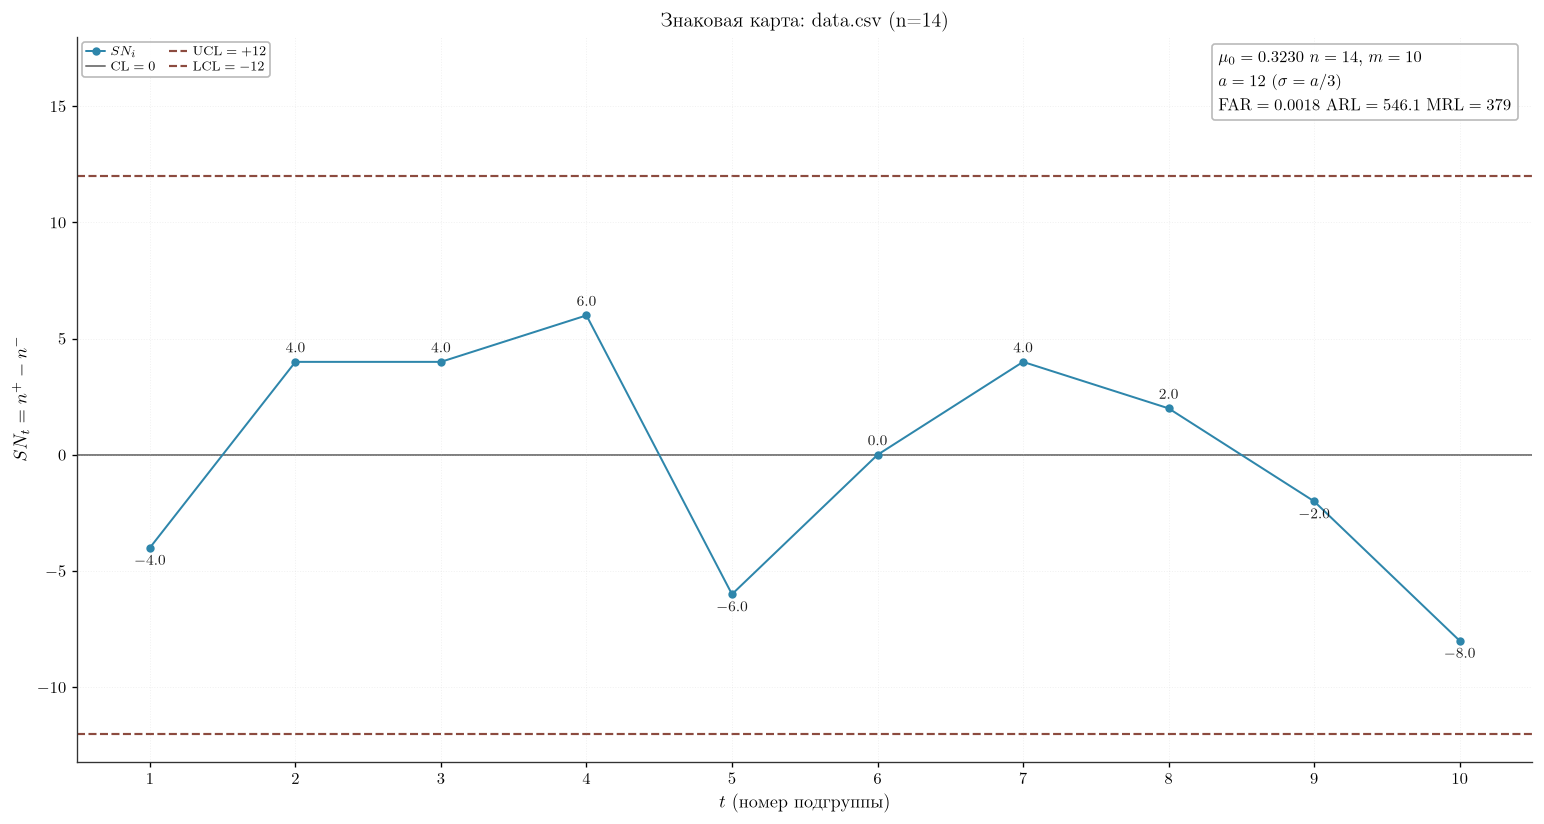

In [5]:
fig, ax = chart.plot(#fill_zones=True,
                     title=f'Знаковая карта: data.csv (n={n})')
plt.show()

### 4.4. Сравнение подходов к выбору $a$

In [6]:
display(chart.compare_approaches().round(6))

,approach,label,a,FAR,ARL_IC,MRL_IC,description
0,exact,"Точный (консервативный, FAR₀)",12,0.001831,546.133333,379,"P(SN ≥ a) ≤ FAR₀/2, FAR₀ = 0.0027"
1,normal,Нормальная аппроксимация,12,0.001831,546.133333,379,"нормальная аппроксимация z·√n, FAR₀ = 0.0027"
2,nearest,Ближайший (α),7,0.057373,17.429787,12,"|P(|SN| ≥ a) − α| → min, α = 0.05"


### 4.5. Знаковый тест и найденные сигналы

In [7]:
test = chart.calculate_sign_test()
print('Знаковый тест по всем наблюдениям:')
for key, val in test.items():
    print(f'  {key:>16} = {val}')

print('\nСигналы |SN| >= a:')
print(chart.get_violations() or 'нет')

Знаковый тест по всем наблюдениям:
    total_positive = 70
    total_negative = 70
             total = 140
           p_value = 1.0
       z_statistic = 0.0
      target_value = 0.323
       significant = False

Сигналы |SN| >= a:
нет


### 4.6. Таблицы и сводка

In [8]:
print('SN по подгруппам:')
display(chart.get_sn_table())

print('Матрица знаков (1 = выше μ₀, −1 = ниже):')
display(chart.get_sign_matrix())

summary = {k: v for k, v in chart.get_summary().items() if k != 'violations'}
display(pd.DataFrame([summary]).T.rename(columns={0: 'значение'}))

SN по подгруппам:


,positive,negative,zero,sn,subgroup
0,5,9,0,-4,1
1,9,5,0,4,2
2,9,5,0,4,3
3,10,4,0,6,4
4,4,10,0,-6,5
5,7,7,0,0,6
6,9,5,0,4,7
7,8,6,0,2,8
8,6,8,0,-2,9
9,3,11,0,-8,10


Матрица знаков (1 = выше μ₀, −1 = ниже):


,subgroup,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14
0,1,-1,1,-1,-1,-1,-1,1,1,-1,1,-1,-1,1,-1
1,2,-1,-1,-1,1,1,1,-1,1,1,1,-1,1,1,1
2,3,-1,1,1,1,1,1,-1,1,-1,-1,1,1,1,-1
3,4,1,1,-1,-1,1,1,1,1,-1,-1,1,1,1,1
4,5,-1,-1,-1,1,1,-1,-1,-1,-1,-1,1,1,-1,-1
5,6,-1,1,-1,1,1,-1,1,-1,1,-1,-1,1,1,-1
6,7,1,1,1,1,1,-1,1,-1,1,-1,-1,1,1,-1
7,8,1,-1,1,1,1,-1,1,-1,1,-1,-1,1,1,-1
8,9,1,-1,-1,-1,1,1,1,-1,-1,-1,-1,1,-1,1
9,10,-1,-1,1,-1,-1,1,1,-1,-1,-1,-1,-1,-1,-1


,значение
chart_type,Sign
approach,exact
target_value,0.323
n,14
a,12
UCL,12
LCL,-12
CL,0
FAR,0.001831
ARL_IC,546.133333


### 4.7. Сравнение подходов на диапазоне $n$

In [9]:
fig, axes = chart.plot_comparison(n_range=np.arange(2, 31))
plt.show()

RuntimeError: latex was not able to process the following string:
b'\\u0422\\u043e\\u0447\\u043d\\u044b\\u0439 (FAR\\u2080 = 0.0027)'

Here is the full command invocation and its output:

latex -interaction=nonstopmode -halt-on-error -no-shell-escape file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.29 (TeX Live 2026/Arch Linux) (preloaded format=latex)
entering extended mode
(./file.tex
LaTeX2e <2025-11-01>
L3 programming layer <2026-01-19>
(/usr/share/texmf-dist/tex/latex/base/fix-cm.sty
(/usr/share/texmf-dist/tex/latex/base/ts1enc.def))
(/usr/share/texmf-dist/tex/latex/base/article.cls
Document Class: article 2025/01/22 v1.4n Standard LaTeX document class
(/usr/share/texmf-dist/tex/latex/base/size10.clo))
(/usr/share/texmf-dist/tex/latex/type1cm/type1cm.sty)
(/usr/share/texmf-dist/tex/latex/base/inputenc.sty)
(/usr/share/texmf-dist/tex/latex/geometry/geometry.sty
(/usr/share/texmf-dist/tex/latex/graphics/keyval.sty)
(/usr/share/texmf-dist/tex/generic/iftex/ifvtex.sty
(/usr/shar

Error in callback <function _draw_all_if_interactive at 0x7f58f5416e50> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: latex was not able to process the following string:
b'\\u0422\\u043e\\u0447\\u043d\\u044b\\u0439 (FAR\\u2080 = 0.0027)'

Here is the full command invocation and its output:

latex -interaction=nonstopmode -halt-on-error -no-shell-escape file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.29 (TeX Live 2026/Arch Linux) (preloaded format=latex)
entering extended mode
(./file.tex
LaTeX2e <2025-11-01>
L3 programming layer <2026-01-19>
(/usr/share/texmf-dist/tex/latex/base/fix-cm.sty
(/usr/share/texmf-dist/tex/latex/base/ts1enc.def))
(/usr/share/texmf-dist/tex/latex/base/article.cls
Document Class: article 2025/01/22 v1.4n Standard LaTeX document class
(/usr/share/texmf-dist/tex/latex/base/size10.clo))
(/usr/share/texmf-dist/tex/latex/type1cm/type1cm.sty)
(/usr/share/texmf-dist/tex/latex/base/inputenc.sty)
(/usr/share/texmf-dist/tex/latex/geometry/geometry.sty
(/usr/share/texmf-dist/tex/latex/graphics/keyval.sty)
(/usr/share/texmf-dist/tex/generic/iftex/ifvtex.sty
(/usr/shar

RuntimeError: latex was not able to process the following string:
b'\\u0422\\u043e\\u0447\\u043d\\u044b\\u0439 (FAR\\u2080 = 0.0027)'

Here is the full command invocation and its output:

latex -interaction=nonstopmode -halt-on-error -no-shell-escape file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.29 (TeX Live 2026/Arch Linux) (preloaded format=latex)
entering extended mode
(./file.tex
LaTeX2e <2025-11-01>
L3 programming layer <2026-01-19>
(/usr/share/texmf-dist/tex/latex/base/fix-cm.sty
(/usr/share/texmf-dist/tex/latex/base/ts1enc.def))
(/usr/share/texmf-dist/tex/latex/base/article.cls
Document Class: article 2025/01/22 v1.4n Standard LaTeX document class
(/usr/share/texmf-dist/tex/latex/base/size10.clo))
(/usr/share/texmf-dist/tex/latex/type1cm/type1cm.sty)
(/usr/share/texmf-dist/tex/latex/base/inputenc.sty)
(/usr/share/texmf-dist/tex/latex/geometry/geometry.sty
(/usr/share/texmf-dist/tex/latex/graphics/keyval.sty)
(/usr/share/texmf-dist/tex/generic/iftex/ifvtex.sty
(/usr/shar

<Figure size 1680x1080 with 2 Axes>

### 4.8. Влияние целевого значения $\mu_0$

In [ ]:
variants = {
    'медиана (по умолчанию)': chart.target_value,
    'среднее': float(data.values.flatten().mean()),
    '0.0': 0.0,
}
rows = []
for name, mu0 in variants.items():
    ch = SignChart(data, sample_size=n, target_value=mu0, approach='exact')
    ch.calculate_limits()
    sn = ch.subgroups['sn'].values
    rows.append({
        'вариант': name, 'μ₀': mu0, 'sum(SN)': int(sn.sum()),
        'a': ch.control_limits['a_value'], 'сигналов': len(ch.get_violations()),
    })
display(pd.DataFrame(rows))

,вариант,μ₀,sum(SN),a,сигналов
0,медиана (по умолчанию),0.323000,0,12,0
1,среднее,0.565938,-56,12,0
2,0.0,0.000000,124,12,7


### 4.9. Проверка инвариантов (capability check)

In [ ]:
checks = {
    'CL = 0': limits['CL'] == 0,
    'UCL = +a': limits['UCL'] == limits['a_value'],
    'LCL = −a': limits['LCL'] == -limits['a_value'],
    '0 < a ≤ n': 0 < limits['a_value'] <= n,
    'FAR ∈ (0, 1]': 0.0 < limits['FAR'] <= 1.0,
    'ARL = 1/FAR': np.isclose(limits['ARL_IC'] * limits['FAR'], 1.0),
    'FAR = 2·P(SN ≥ a)': np.isclose(limits['FAR'],
                                    min(2 * p_sn_ge(n, limits['a_value']), 1.0)),
}
for name, ok in checks.items():
    print(('[OK]   ' if ok else '[FAIL] ') + name)
assert all(checks.values()), 'Инварианты карты нарушены'

[OK]   CL = 0
[OK]   UCL = +a
[OK]   LCL = −a
[OK]   0 < a ≤ n
[OK]   FAR ∈ (0, 1]
[OK]   ARL = 1/FAR
[OK]   FAR = 2·P(SN ≥ a)


## 5. Итог

| Величина | Формула | Источник |
| --- | --- | --- |
| Знаковая статистика | $SN_i = n_i^+ - n_i^- = 2T_i - n$ | ур. 4.1, стр. 190 |
| Распределение в IC | $T_i \sim \mathrm{BIN}(n, 1/2)$ | стр. 192 |
| Моменты | $E(SN_i) = 0$, $\mathrm{Var}(SN_i) = n$ | табл. 4.1, стр. 193 |
| Границы | $LCL = -a$, $CL = 0$, $UCL = +a$ | ур. 4.3, стр. 190 |
| Выбор $a$ | $P(SN \ge a) \le FAR_0/2$ (наименьшее) | стр. 191 |
| Длина серии | $N \sim \mathrm{GEO}(FAR)$ | стр. 192–193 |

**Выводы.**

1. Знаковая карта distribution-free для всех непрерывных $F$; плата — обычно $n \ge 10$.
2. На графике зоны подписаны в единицах $\sigma = a/3$ (соглашение о разметке).
   Истинное стандартное отклонение статистики — $SD(SN) = \sqrt{n}$ (табл. 4.1).
3. Примеры 4.1–4.3 проверяются автотестами `tests/sign/`.